In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 7\Stock_Prices.csv"

df = pd.read_csv(DATA_PATH)

df.head()

,Price,Close,High,Low,Open,Volume
0,Ticker,BEL.NS,BEL.NS,BEL.NS,BEL.NS,BEL.NS
1,Date,NaN,NaN,NaN,NaN,NaN
2,2012-01-02,10.757936477661133,10.93730810375916,10.666858300644368,10.778219630865577,1220472
3,2012-01-03,11.044294357299805,11.187871559035488,10.746799361241878,10.976284064319463,910008
4,2012-01-04,11.253098487854004,11.35571136451063,10.950036252453096,10.950036252453096,2594493


In [3]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (3205, 6)

Column Names:
['Price', 'Close', 'High', 'Low', 'Open', 'Volume']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3205 entries, 0 to 3204
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   Price   3205 non-null   object
 1   Close   3204 non-null   object
 2   High    3204 non-null   object
 3   Low     3204 non-null   object
 4   Open    3204 non-null   object
 5   Volume  3204 non-null   object
dtypes: object(6)
memory usage: 150.4+ KB


In [4]:
print("Missing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Missing Values:
Price     0
Close     1
High      1
Low       1
Open      1
Volume    1
dtype: int64

Duplicate Rows: 0


In [7]:
print(df.columns.tolist())

['Price', 'Close', 'High', 'Low', 'Open', 'Volume']


In [8]:
print(df.index)
print(df.head())

RangeIndex(start=0, stop=3205, step=1)
        Price               Close                High                 Low  \
0      Ticker              BEL.NS              BEL.NS              BEL.NS   
1        Date                 NaN                 NaN                 NaN   
2  2012-01-02  10.757936477661133   10.93730810375916  10.666858300644368   
3  2012-01-03  11.044294357299805  11.187871559035488  10.746799361241878   
4  2012-01-04  11.253098487854004   11.35571136451063  10.950036252453096   

                 Open   Volume  
0              BEL.NS   BEL.NS  
1                 NaN      NaN  
2  10.778219630865577  1220472  
3  10.976284064319463   910008  
4  10.950036252453096  2594493  


In [9]:
df = df.iloc[2:].copy()
df = df.rename(columns={"Price": "Date"})

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

for col in ["Close", "High", "Low", "Open", "Volume"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna()

print(df.head())
print("\nDataset Shape:", df.shape)
print("\nDate Range:", df["Date"].min(), "to", df["Date"].max())

        Date      Close       High        Low       Open   Volume
0 2012-01-02  10.757936  10.937308  10.666858  10.778220  1220472
1 2012-01-03  11.044294  11.187872  10.746799  10.976284   910008
2 2012-01-04  11.253098  11.355711  10.950036  10.950036  2594493
3 2012-01-05  11.224859  11.279347  11.104351  11.136168  2890008
4 2012-01-06  11.186677  11.311164  10.978272  11.207359  1299870

Dataset Shape: (3203, 6)

Date Range: 2012-01-02 00:00:00 to 2024-12-30 00:00:00


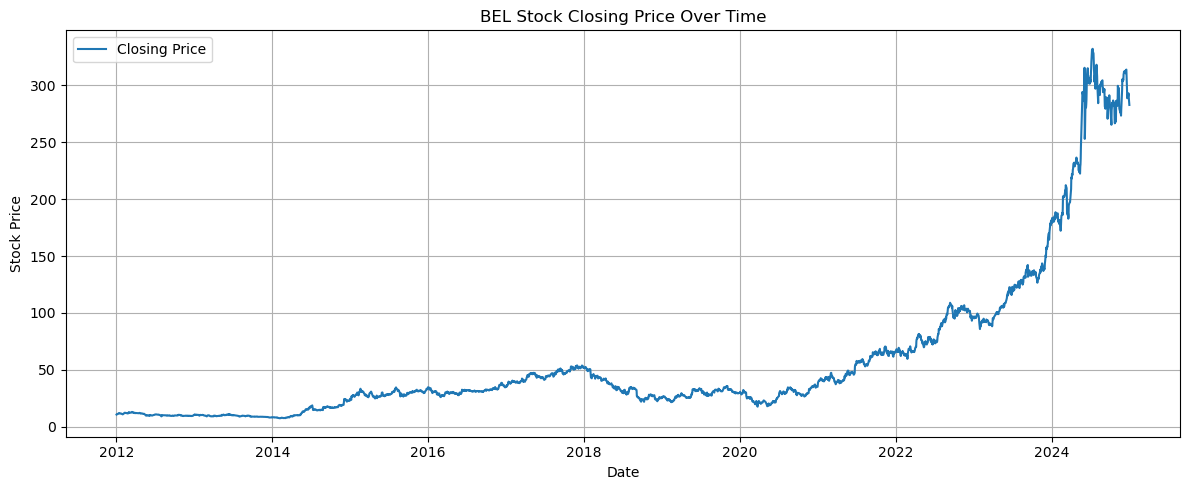

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"], label="Closing Price")
plt.title("BEL Stock Closing Price Over Time")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

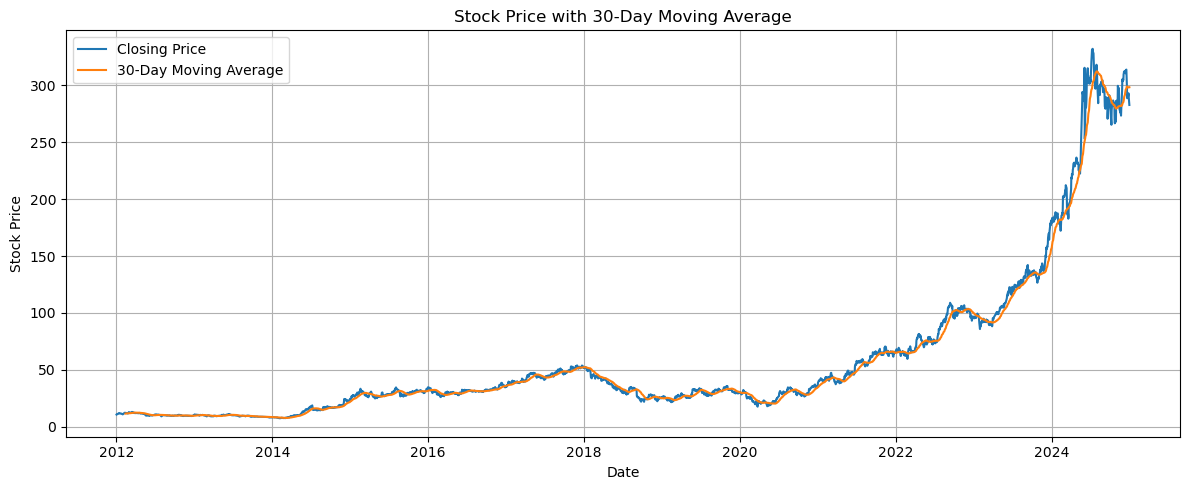

In [11]:
df["MA_30"] = df["Close"].rolling(window=30).mean()

plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"], label="Closing Price")
plt.plot(df["Date"], df["MA_30"], label="30-Day Moving Average")
plt.title("Stock Price with 30-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

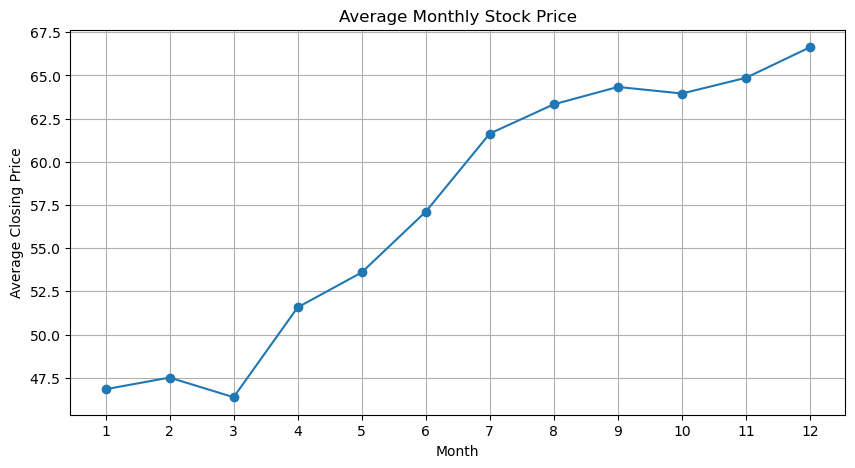

In [12]:
df["Month"] = df["Date"].dt.month
df["Year"] = df["Date"].dt.year

monthly_sales = df.groupby("Month")["Close"].mean()

plt.figure(figsize=(10, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Average Monthly Stock Price")
plt.xlabel("Month")
plt.ylabel("Average Closing Price")
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

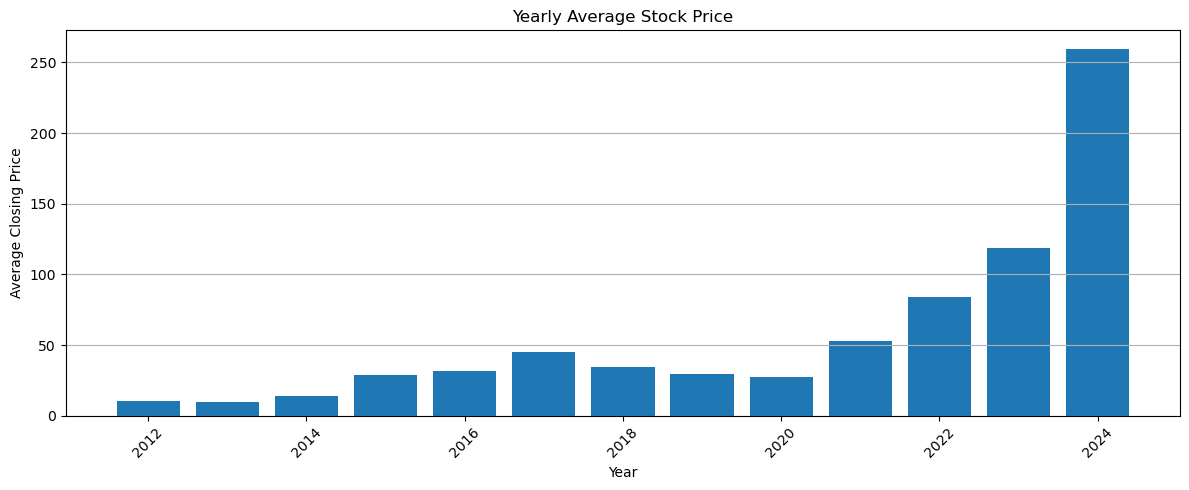

In [13]:
yearly_sales = df.groupby("Year")["Close"].mean()

plt.figure(figsize=(12, 5))
plt.bar(yearly_sales.index, yearly_sales.values)
plt.title("Yearly Average Stock Price")
plt.xlabel("Year")
plt.ylabel("Average Closing Price")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

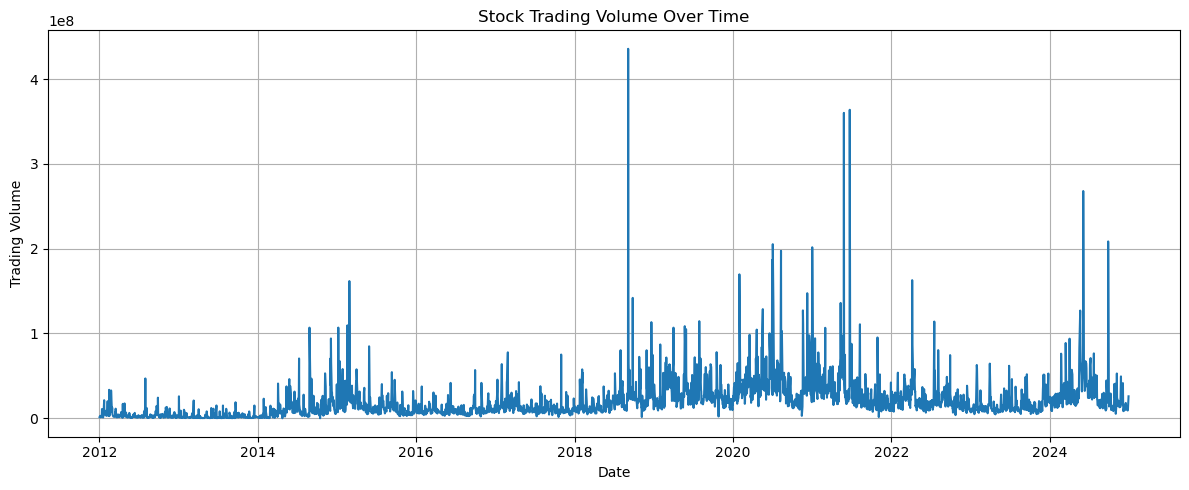

In [14]:
plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Volume"])
plt.title("Stock Trading Volume Over Time")
plt.xlabel("Date")
plt.ylabel("Trading Volume")
plt.grid(True)
plt.tight_layout()
plt.show()

Correlation Matrix:
           Close    Volume
Close   1.000000  0.144391
Volume  0.144391  1.000000


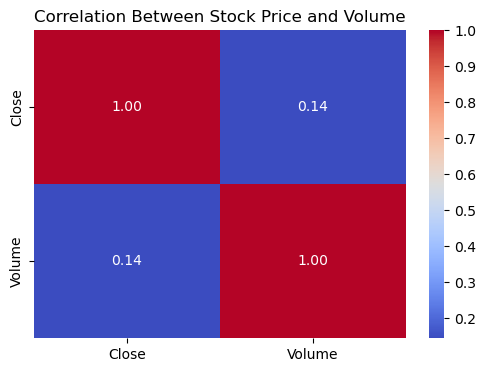

In [15]:
correlation = df[["Close", "Volume"]].corr()

print("Correlation Matrix:")
print(correlation)

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Stock Price and Volume")
plt.show()

C:\Users\Akshay\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)
C:\Users\Akshay\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: ValueWarning: No supported index is available. Prediction results will be given with an integer index beginning at `start`.
  return get_prediction_index(
C:\Users\Akshay\anaconda3\Lib\site-packages\statsmodels\tsa\base\tsa_model.py:837: FutureWarning: No supported index is available. In the next version, calling this method in a model without a supported index will result in an exception.
  return get_prediction_index(


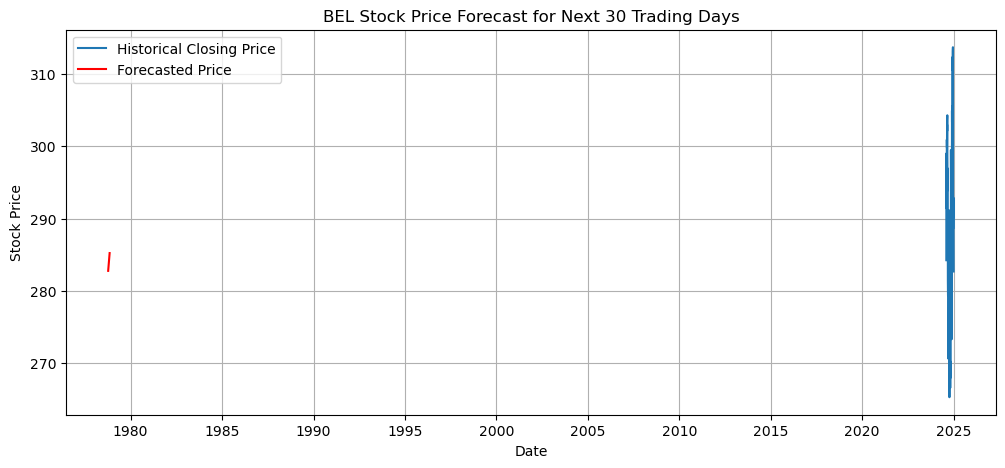

Forecasted Stock Prices:
3203    282.762500
3204    282.847404
3205    282.932307
3206    283.017210
3207    283.102113
3208    283.187016
3209    283.271920
3210    283.356823
3211    283.441726
3212    283.526629
3213    283.611532
3214    283.696436
3215    283.781339
3216    283.866242
3217    283.951145
3218    284.036048
3219    284.120952
3220    284.205855
3221    284.290758
3222    284.375661
3223    284.460564
3224    284.545467
3225    284.630371
3226    284.715274
3227    284.800177
3228    284.885080
3229    284.969983
3230    285.054887
3231    285.139790
3232    285.224693
dtype: float64


In [16]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

stock_data = df.set_index("Date")["Close"]

model = ExponentialSmoothing(stock_data, trend="add", seasonal=None)
model_fit = model.fit()

forecast = model_fit.forecast(30)

plt.figure(figsize=(12, 5))
plt.plot(stock_data.tail(100), label="Historical Closing Price")
plt.plot(forecast, label="Forecasted Price", color="red")
plt.title("BEL Stock Price Forecast for Next 30 Trading Days")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.show()

print("Forecasted Stock Prices:")
print(forecast)

In [17]:
print("Stock Market Analysis Summary")
print("Total Records:", len(df))
print("Date Range:", df["Date"].min(), "to", df["Date"].max())
print("Average Closing Price:", df["Close"].mean())
print("Highest Closing Price:", df["Close"].max())
print("Lowest Closing Price:", df["Close"].min())
print("Average Trading Volume:", df["Volume"].mean())

Stock Market Analysis Summary
Total Records: 3203
Date Range: 2012-01-02 00:00:00 to 2024-12-30 00:00:00
Average Closing Price: 57.35869974454343
Highest Closing Price: 331.9806213378906
Lowest Closing Price: 7.524012565612793
Average Trading Volume: 20244522.673118953


In [19]:
OUTPUT_PATH = r"C:\Users\Akshay\OneDrive\Desktop\DMV & ML Practical\DMV Practical\DMV 7\Cleaned_stock_market_analysis.csv"

df.to_csv(OUTPUT_PATH, index=False)

print("Stock market analysis dataset saved successfully!")

Stock market analysis dataset saved successfully!
